# Laboratório 1 — Modelos intrinsecamente interpretáveis

**PGENE587 — Inteligência Artificial Explicável**

---

## A pergunta do laboratório

Em aula discutimos a base empírica da tese de Rudin (2019): em problemas com dados estruturados e
atributos com significado relevante ao domínio, modelos interpretáveis costumam alcançar acurácia
equivalente à de modelos caixa-preta. Vamos medir essa afirmação.

Neste laboratório vocês vão produzir **evidência própria** sobre esse trade-off,
comparando quatro famílias de modelos no mesmo problema em três eixos:

1. **acurácia** — incluindo a incerteza;
2. **complexidade da explicação** — quantos elementos ela possui;
3. **estabilidade** — se a explicação é robusta à reamostragem dos dados.


## Tarefas

| # | Tarefa | Produto |
|---|---|---|
| 1 | Preparar dados e divisão | Conjuntos de treino e teste, semente fixa |
| 2 | Ajustar quatro modelos | Linear/logístico, árvore, EBM, gradient boosting |
| 3 | Medir acurácia com incerteza | Tabela com intervalo por reamostragem |
| 4 | Medir complexidade | Contagem de elementos da explicação por modelo |
| 5 | Medir estabilidade | Frequência de troca do topo do ranking em 10 bootstraps |
| 6 | Ler uma função de forma | Uma figura e uma leitura de domínio |
| 7 | Síntese | Escolha justificada de um modelo para um público nomeado |


## Como este laboratório é avaliado

| Peso | Critério | O que significa na prática |
|---|---|---|
| 40% | **Medidas corretas** | Os números pedidos foram produzidos, com o procedimento correto. |
| 30% | **Discussão** | Cada conclusão aponta para um número deste notebook. |
| 20% | **Reprodutibilidade** | Executa de ponta a ponta, semente fixa, ambiente declarado, sem células mortas. |
| 10% | **Clareza** | Figuras com eixos rotulados, escala declarada e uma pergunta escrita antes de cada uma. |


---
## 0. Ambiente

A primeira célula fixa a semente e imprime as versões. **Não a altere**: a semente
é o que torna o seu resultado verificável.

In [1]:
# Ambiente — execute uma vez. No Colab, descomente a linha de instalação.
!pip -q install interpret scikit-learn pandas matplotlib

import os, sys, json, time, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMENTE = 20262
random.seed(SEMENTE); np.random.seed(SEMENTE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "axes.titlesize": 11, "axes.titleweight": "bold",
})
COR = {"a": "#3B3FBF", "b": "#F2A93B", "c": "#61648A", "d": "#4C8DF6", "e": "#B85042"}

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("Semente fixa:", SEMENTE)



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Python 3.12.2 | numpy 2.5.3 | pandas 3.0.6
Semente fixa: 20262


In [2]:
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, roc_auc_score, accuracy_score
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils import resample
from itertools import combinations

try:
    from interpret.glassbox import ExplainableBoostingRegressor, ExplainableBoostingClassifier
    import interpret
    TEM_EBM = True
    print("interpret", interpret.__version__)
except Exception as e:
    print('interpret indisponível (%s). O EBM será substituído por um GAM por splines.' % type(e).__name__)
    TEM_EBM = False

import sklearn
print("scikit-learn", sklearn.__version__)

interpret 0.7.8
scikit-learn 1.9.1


---
## 1. Dados

O carregador abaixo tenta, nesta ordem: um CSV local em `dados/`, o OpenML, e por fim
um conjunto embutido no scikit-learn como **substituto declarado**. Ele sempre imprime
a fonte usada — anote-a, porque ela entra no seu relatório.

Escolha **uma** das duas tarefas e siga com ela até o fim: regressão (aluguel de
bicicletas) ou classificação binária (risco).

In [ ]:
# Base de dados utilizada é a disponibilizada pela disciplina

from sklearn.datasets import fetch_openml, load_diabetes, load_breast_cancer

PASTA_DADOS = "dados"


def _tenta_local(nome):
    caminho = os.path.join(PASTA_DADOS, nome)
    if os.path.exists(caminho):
        return pd.read_csv(caminho)
    return None


def carregar_bicicletas():
    """Regressão: contagem de aluguéis de bicicletas. Devolve (X, y, fonte)."""
    df = _tenta_local("bike.csv")
    if df is not None:
        y = df.pop("count" if "count" in df else df.columns[-1])
        print("Fonte: CSV local dados/bike.csv")
        return df, y, "local"

    try:
        d = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True, parser="auto")
        X = d.frame.drop(columns=[d.target_names[0]])
        y = d.frame[d.target_names[0]]
        print("Fonte: OpenML — Bike_Sharing_Demand")
        return X, y, "openml"
    except Exception as e:
        print("OpenML indisponível (%s: %s)" % (type(e).__name__, e))

    d = load_diabetes(as_frame=True)
    print("Fonte: SUBSTITUTO — sklearn load_diabetes (declare isso no relatório)")
    return d.data, d.target, "substituto"


def carregar_risco():
    """Classificação binária de risco. Devolve (X, y, fonte)."""
    df = _tenta_local("cervical.csv")
    if df is not None:
        y = df.pop(df.columns[-1])
        print("Fonte: CSV local dados/cervical.csv")
        return df, y, "local"

    for nome in ("credit-g", "diabetes"):
        try:
            d = fetch_openml(nome, version=1, as_frame=True, parser="auto")
            X = pd.get_dummies(d.data, drop_first=True).astype(float)
            y = (d.target == d.target.unique()[0]).astype(int)
            print("Fonte: OpenML —", nome)
            return X, y, "openml"
        except Exception as e:
            print("OpenML/%s indisponível (%s)" % (nome, type(e).__name__))

    d = load_breast_cancer(as_frame=True)
    print("Fonte: SUBSTITUTO — sklearn load_breast_cancer (declare isso no relatório)")
    return d.data, d.target, "substituto"


def dividir(X, y, teste=0.25):
    from sklearn.model_selection import train_test_split
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=teste, random_state=SEMENTE)
    print(f"treino: {len(Xtr)} | teste: {len(Xte)} | atributos: {X.shape[1]}")
    return Xtr, Xte, ytr, yte


In [4]:
TAREFA = 'regressao'   # 'regressao' ou 'classificacao'

MAX_CATEGORIAS = 20      # acima disso, a coluna categórica não passa por one-hot
LIMIAR_ID = 0.95         # fração de valores únicos a partir da qual a coluna é tratada como id

def limpar_colunas(X, max_categorias=MAX_CATEGORIAS, limiar_id=LIMIAR_ID):
    n = len(X)
    removidas = {}
    for col in X.columns:
        n_unicos = X[col].nunique(dropna=True)
        eh_categorica = not pd.api.types.is_numeric_dtype(X[col])

        if n_unicos <= 1:
            removidas[col] = 'constante'
        elif eh_categorica and n_unicos / n >= limiar_id:
            removidas[col] = 'identificador/data (um valor por linha)'
        elif eh_categorica and n_unicos > max_categorias:
            removidas[col] = f'categórica com {n_unicos} valores'
    for col, motivo in removidas.items():
        print(f'  removendo {col!r}: {motivo}')
    return X.drop(columns=list(removidas))



DESNORM = {"temp": (-8, 47, (-8, 39)), "umidade": (0, 100, (0, 100)), "vento": (0, 67, (0, 35))}

def _candidatos(v, lo, hi):
    sinal = -1.0 if v.strip().startswith("-") else 1.0
    dig = v.replace("-", "").replace(".", "").replace(",", "").strip()
    c = [sinal * float(dig[:k] + "." + dig[k:]) for k in (1, 2, 3) if k < len(dig)] or [sinal * float(dig)]
    return [x for x in c if lo <= x <= hi] or c

def corrige_numero_texto(serie, desloc, escala, faixa):
    saida, anterior = [], (faixa[0] + faixa[1]) / 2
    for v in serie.astype(str):
        cands = _candidatos(v, *faixa)
        exatos = [c for c in cands
                  if abs((c - desloc) / escala * 1e6 - round((c - desloc) / escala * 1e6)) < 0.02]
        esc = min(exatos or cands, key=lambda c: abs(c - anterior))
        saida.append(esc); anterior = esc
    return pd.Series(saida, index=serie.index, dtype=float)

def corrige_sensacao(serie, temp, faixa=(-16, 50)):
    return pd.Series([min(_candidatos(v, *faixa), key=lambda c: abs(c - t))
                      for v, t in zip(serie.astype(str), temp)], index=serie.index, dtype=float)

def prepara_bike(X):
    X = X.copy()
    for col, (desloc, escala, faixa) in DESNORM.items():
        if col in X and not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = corrige_numero_texto(X[col], desloc, escala, faixa)
            print(f'  corrigindo {col!r}: texto -> número (min {X[col].min():.2f}, max {X[col].max():.2f})')
    if "sensacao" in X and not pd.api.types.is_numeric_dtype(X["sensacao"]):
        X["sensacao"] = corrige_sensacao(X["sensacao"], X["temp"])
        print(f'  corrigindo \'sensacao\': texto -> número (min {X["sensacao"].min():.2f}, max {X["sensacao"].max():.2f})')
    vazamento = [c for c in ("casuais", "registrados", "estacao_rotulo", "tempo_rotulo") if c in X]
    for c in vazamento:
        print(f'  removendo {c!r}:', 'componente do alvo (vazamento)' if c in ("casuais", "registrados")
              else 'rótulo textual duplicado')
    return X.drop(columns=vazamento)


if TAREFA == 'regressao':
    X, y, fonte = carregar_bicicletas()
    if fonte == 'local':
        X = prepara_bike(X)
else:
    X, y, fonte = carregar_risco()

X = limpar_colunas(X)

colunas_cat = X.select_dtypes(exclude='number').columns
X = pd.get_dummies(X, columns=colunas_cat, drop_first=True).astype(float)
X = X.fillna(X.median(numeric_only=True))
y = pd.Series(np.asarray(y, dtype=float), index=X.index)
Xtr, Xte, ytr, yte = dividir(X, y)
X.head()

Fonte: OpenML — Bike_Sharing_Demand
treino: 13034 | teste: 4345 | atributos: 16


,year,month,hour,weekday,temp,feel_temp,humidity,windspeed,season_spring,season_summer,season_winter,holiday_True,workingday_True,weather_heavy_rain,weather_misty,weather_rain
0,0.0,1.0,0.0,6.0,9.84,14.395,0.81,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,1.0,6.0,9.02,13.635,0.80,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,2.0,6.0,9.02,13.635,0.80,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,3.0,6.0,9.84,14.395,0.75,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,4.0,6.0,9.84,14.395,0.75,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 1.1 Analise os dados antes de modelar

Antes de qualquer explicação, é preciso saber com o que se está lidando. A célula
abaixo deve produzir: (a) a distribuição do alvo, (b) o mapa de correlação entre
atributos.

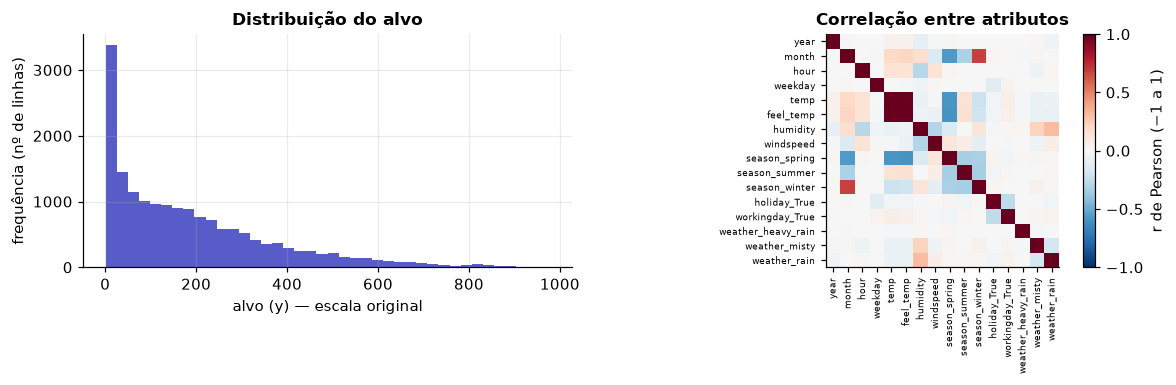

pares com |r| > 0.7: 1
  temp ~ feel_temp: r = 0.99


In [5]:
# Pergunta que a figura responde: o alvo é assimétrico? Há atributos redundantes entre si?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

# (a) distribuição do alvo
ax[0].hist(y, bins=40, color=COR["a"], alpha=0.85)
ax[0].set_xlabel("alvo (y) — escala original")
ax[0].set_ylabel("frequência (nº de linhas)")
ax[0].set_title("Distribuição do alvo")

# (b) correlação de Pearson entre atributos
corr = X.corr()
im = ax[1].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr.columns)))
ax[1].set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax[1].set_yticks(range(len(corr.columns)))
ax[1].set_yticklabels(corr.columns, fontsize=6)
ax[1].grid(False)
ax[1].set_title("Correlação entre atributos")
fig.colorbar(im, ax=ax[1], label="r de Pearson (−1 a 1)")
plt.tight_layout(); plt.show()

# pares distintos (triângulo superior, sem a diagonal) com |r| > 0.7
sup = np.triu(np.abs(corr.fillna(0).values), k=1)
n_pares_correlacionados = int((sup > 0.7).sum())
print('pares com |r| > 0.7:', n_pares_correlacionados)

i, j = np.where(sup > 0.7)
for a, b in zip(i, j):
    print(f"  {corr.columns[a]} ~ {corr.columns[b]}: r = {corr.iloc[a, b]:.2f}")

**Discussão 1.** O que a distribuição do alvo e o número de pares correlacionados já permitem antecipar sobre as explicações que virão? Cite o número que você obteve.

O alvo, **aluguéis por hora**, apresenta forte assimetria à direita, com grande concentração de horas registrando poucos ou nenhum aluguel e uma cauda longa que se aproxima de 1000 aluguéis. Essa distribuição indica que o **MAE tende a ser mais influenciado pelos períodos de pico**, nos quais os erros absolutos são maiores, além de representar um desafio para modelos lineares, que podem ter dificuldade em capturar esse comportamento não linear.

Na análise de correlação entre os atributos, foi identificado **1 par com |r| > 0,7**: `temp` e `feel_temp`, que apresentam correlação de **r = 0,99**. Na prática, os dois atributos carregam informações muito semelhantes. Como consequência, alguns modelos podem distribuir a importância entre essas variáveis de forma arbitrária, tornando o ranking de importância menos estável. Esse efeito é especialmente relevante na interpretação de modelos lineares, nos quais a presença de atributos fortemente correlacionados pode dificultar a avaliação individual da contribuição de cada variável.


---
## 2. Quatro modelos

Ajuste as quatro famílias. Mantenha os hiperparâmetros modestos: o objetivo não é otimizar e encontrar o melhor modelo, é comparar famílias em condições parecidas.

* **Linear / logístico** — sobre atributos padronizados, para que os coeficientes sejam comparáveis.
* **Árvore** — profundidade limitada a 4, para que continue simulável.
* **EBM** — modelo aditivo por boosting cíclico.
* **Gradient boosting** — referência de acurácia, sem pretensão de interpretabilidade.

In [6]:
def constroi_modelos(tarefa):
    """Devolve um dicionário {nome: estimador} para a tarefa escolhida."""
    reg = (tarefa == 'regressao')

    if reg:
        linear = Pipeline([("padroniza", StandardScaler()), ("modelo", LinearRegression())])
        arvore = DecisionTreeRegressor(max_depth=4, random_state=SEMENTE)
        gb = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.1,
                                       random_state=SEMENTE)
    else:
        linear = Pipeline([("padroniza", StandardScaler()),
                           ("modelo", LogisticRegression(max_iter=2000))])
        arvore = DecisionTreeClassifier(max_depth=4, random_state=SEMENTE)
        gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                        random_state=SEMENTE)

    if TEM_EBM:
        Ebm = ExplainableBoostingRegressor if reg else ExplainableBoostingClassifier
        aditivo = Ebm(random_state=SEMENTE)
    else:
        # GAM substituto: base de splines por atributo + modelo linear regularizado
        final = Ridge(alpha=1.0) if reg else LogisticRegression(max_iter=2000)
        aditivo = Pipeline([("padroniza", StandardScaler()),
                            ("splines", SplineTransformer(n_knots=6, degree=3)),
                            ("modelo", final)])

    return {"linear": linear, "arvore": arvore, "ebm": aditivo, "gradient_boosting": gb}

modelos = constroi_modelos(TAREFA)
for nome, m in modelos.items():
    t0 = time.time(); m.fit(Xtr, ytr)
    print(f'{nome:22s} treinado em {time.time()-t0:5.1f}s')

linear                 treinado em   0.1s
arvore                 treinado em   0.0s
ebm                    treinado em  45.4s
gradient_boosting      treinado em   1.6s


---
## 3. Acurácia com incerteza

Estime o desempenho no conjunto de teste com um
intervalo obtido por reamostragem bootstrap **do conjunto de teste** (200 reamostras),
e reporte a mediana e o intervalo de 5% a 95%.

> Métrica: MAE para regressão, AUC para classificação.

In [7]:
def _saida(modelo, Xa):
    """Predição (regressão) ou probabilidade da classe positiva (classificação)."""
    if TAREFA == 'regressao':
        return np.asarray(modelo.predict(Xa))
    return np.asarray(modelo.predict_proba(Xa)[:, 1])

def _pontua(ya, saida):
    if TAREFA == 'regressao':
        return mean_absolute_error(ya, saida)
    return roc_auc_score(ya, saida)

def metrica(modelo, Xa, ya):
    """MAE (regressão) ou AUC (classificação)."""
    return _pontua(np.asarray(ya), _saida(modelo, Xa))

def desempenho_com_intervalo(modelo, Xa, ya, n_boot=200):
    """Devolve (mediana, p05, p95) por bootstrap do conjunto de avaliação."""
    rng = np.random.RandomState(SEMENTE)       # mesmas reamostras para todos os modelos
    ya = np.asarray(ya)
    saida = _saida(modelo, Xa)                 # o modelo não é reajustado: só o teste é reamostrado
    n = len(ya)
    valores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        if TAREFA != 'regressao' and len(np.unique(ya[idx])) < 2:
            continue                           # AUC indefinida com uma só classe
        valores.append(_pontua(ya[idx], saida[idx]))
    valores = np.asarray(valores)
    return np.median(valores), np.percentile(valores, 5), np.percentile(valores, 95)

linhas = []
for nome, m in modelos.items():
    med, lo, hi = desempenho_com_intervalo(m, Xte, yte)
    linhas.append({'modelo': nome, 'metrica': round(med, 4),
                   'p05': round(lo, 4), 'p95': round(hi, 4)})
tabela_acuracia = pd.DataFrame(linhas)
tabela_acuracia["largura_intervalo"] = (tabela_acuracia["p95"] - tabela_acuracia["p05"]).round(4)
tabela_acuracia

,modelo,metrica,p05,p95,largura_intervalo
0,linear,103.4717,101.3693,105.7130,4.3437
1,arvore,80.9289,78.6393,83.0594,4.4201
2,ebm,33.8094,32.8813,34.9430,2.0617
3,gradient_boosting,40.8140,39.6331,42.0626,2.4295


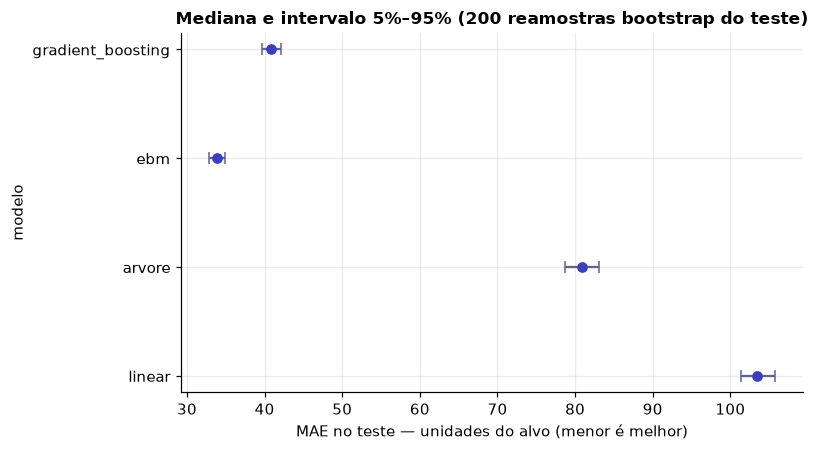

melhor interpretável: ebm | diferença para o GB: 7.0046 | largura do intervalo do GB: 2.4295


In [8]:
# Pergunta que a figura responde: "a diferença entre o melhor modelo interpretável e o
# gradient boosting é maior do que a incerteza da estimativa?"
t = tabela_acuracia
pos = np.arange(len(t))
fig, ax = plt.subplots()
ax.errorbar(t["metrica"], pos,
            xerr=[t["metrica"] - t["p05"], t["p95"] - t["metrica"]],
            fmt="o", color=COR["a"], ecolor=COR["c"], capsize=4)
ax.set_yticks(pos); ax.set_yticklabels(t["modelo"])
if TAREFA == 'regressao':
    ax.set_xlabel("MAE no teste — unidades do alvo (menor é melhor)")
else:
    ax.set_xlabel("AUC no teste — escala 0 a 1 (maior é melhor)")
ax.set_ylabel("modelo")
ax.set_title("Mediana e intervalo 5%–95% (200 reamostras bootstrap do teste)")
plt.tight_layout(); plt.show()

# diferença entre o melhor interpretável e o GB, comparada à largura do intervalo do GB
interp = t[t["modelo"] != "gradient_boosting"]
melhor = interp.loc[interp["metrica"].idxmin() if TAREFA == 'regressao' else interp["metrica"].idxmax()]
gb_lin = t[t["modelo"] == "gradient_boosting"].iloc[0]
print(f"melhor interpretável: {melhor['modelo']} | diferença para o GB: "
      f"{abs(melhor['metrica'] - gb_lin['metrica']):.4f} | largura do intervalo do GB: "
      f"{gb_lin['p95'] - gb_lin['p05']:.4f}")

**Discussão 2.** A diferença de desempenho entre o melhor modelo interpretável e o gradient boosting é maior ou menor que a largura do intervalo de incerteza? O que isso diz sobre a tese de Rudin *neste* conjunto de dados — e apenas neste?

O **EBM foi o melhor modelo interpretável**, com MAE de **33,8** (intervalo de 5% a 95%: **32,9 a 34,9**), enquanto o Gradient Boosting apresentou MAE de **40,8** (39,6 a 42,1). A diferença de **7,0 pontos** é maior que a largura do intervalo do Gradient Boosting (**2,4 pontos**), e os intervalos não se sobrepõem. Portanto, o EBM não apenas teve desempenho semelhante ao modelo de referência, mas apresentou resultado superior neste conjunto de dados. Esse resultado está de acordo com a ideia defendida por Rudin de que modelos interpretáveis podem alcançar desempenho competitivo, e até superior, ao de modelos caixa-preta. Ainda assim, essa conclusão deve ser limitada ao experimento realizado, já que o Gradient Boosting foi configurado com parâmetros relativamente simples, usando 200 árvores e profundidade 3, e a análise foi feita em apenas um conjunto de dados.

Também é importante observar que o bom resultado não ocorreu com todos os modelos interpretáveis. O modelo linear apresentou MAE de **103,5**, enquanto a árvore de decisão ficou em **80,9**, ambos bem abaixo do EBM. Uma possível explicação está no comportamento da variável `hour`, que apresenta um padrão cíclico, com aumento dos aluguéis pela manhã e no fim da tarde. Esse tipo de relação é difícil de representar com uma reta e também fica limitado em uma árvore com profundidade 4.


---
## 4. Complexidade da explicação

Acurácia comparável não basta: a pergunta seguinte é quanto custa **ler** cada modelo.
Conte, para cada família, o número de elementos que alguém precisaria examinar para
entender uma predição.

| Modelo | Unidade de contagem |
|---|---|
| Linear / logístico | coeficientes não nulos (acima de um limiar) |
| Árvore | número de folhas e profundidade média do caminho |
| EBM | funções de forma (uma por atributo) e termos de interação |
| Gradient boosting | número de árvores × folhas por árvore |

In [9]:
LIMIAR_COEF = 0.01   # coeficiente "não nulo" = |coef| acima de 1% do maior |coef|

def _estimador_final(modelo):
    """Num Pipeline, o estimador é o último passo."""
    return modelo.steps[-1][1] if hasattr(modelo, "steps") else modelo

def complexidade(nome, modelo):
    """Devolve um dicionário com a contagem apropriada ao modelo."""
    est = _estimador_final(modelo)

    if hasattr(est, "term_names_"):                       # EBM
        termos = list(est.term_names_)
        n_int = sum(" & " in t for t in termos)
        return {"modelo": nome, "unidade": "funções de forma + interações",
                "elementos": len(termos),
                "detalhe": f"{len(termos) - n_int} funções de forma, {n_int} interações"}

    if hasattr(est, "estimators_") and hasattr(est, "n_estimators_"):   # gradient boosting
        folhas = [a.tree_.n_leaves for a in np.ravel(est.estimators_)]
        return {"modelo": nome, "unidade": "árvores × folhas",
                "elementos": int(np.sum(folhas)),
                "detalhe": f"{len(folhas)} árvores × {np.mean(folhas):.1f} folhas em média"}

    if hasattr(est, "tree_"):                             # árvore única
        folhas = int(est.get_n_leaves())
        # profundidade média do caminho percorrido pelas observações de TESTE
        prof = float((np.asarray(est.decision_path(Xte).sum(axis=1)).ravel() - 1).mean())
        return {"modelo": nome, "unidade": "folhas (prof. média do caminho)",
                "elementos": folhas,
                "detalhe": f"{folhas} folhas, profundidade média do caminho {prof:.2f}"}

    if hasattr(est, "coef_"):                             # linear / logístico (ou GAM substituto)
        c = np.abs(np.ravel(est.coef_))
        n = int((c > LIMIAR_COEF * c.max()).sum())
        unidade = "coef. de splines não nulos" if "splines" in getattr(modelo, "named_steps", {}) \
                  else "coeficientes não nulos"
        return {"modelo": nome, "unidade": unidade, "elementos": n,
                "detalhe": f"{n} de {len(c)} acima de {LIMIAR_COEF:.0%} do maior |coef|"}

    raise ValueError(f"família não reconhecida: {nome}")

tabela_complexidade = pd.DataFrame([complexidade(n, m) for n, m in modelos.items()])
tabela_complexidade

,modelo,unidade,elementos,detalhe
0,linear,coeficientes não nulos,16,16 de 16 acima de 1% do maior |coef|
1,arvore,folhas (prof. média do caminho),16,"16 folhas, profundidade média do caminho 4.00"
2,ebm,funções de forma + interações,96,"16 funções de forma, 80 interações"
3,gradient_boosting,árvores × folhas,1600,200 árvores × 8.0 folhas em média


**Discussão 3.** Ordene os quatro modelos por “custo de leitura” e diga, para cada um, qual é o público que ainda conseguiria lê-lo. Onde está a fronteira entre “explicação” e “documentação técnica”?

Pelo custo de leitura, a ordem é: **(1) linear**, com 16 coeficientes; **(2) árvore**, com 16 folhas; **(3) EBM**, com 96 termos; e **(4) Gradient Boosting**, com 1.600 folhas.

O linear e a árvore são fáceis de acompanhar por um gestor. No EBM, as 16 funções de forma ainda são legíveis, mas as 80 interações já exigem mais conhecimento técnico. No Gradient Boosting, a quantidade de folhas torna a leitura completa impraticável.

Na prática, considero que a explicação deixa de ser útil quando não é mais possível examinar os elementos do modelo para entender uma previsão. Nesse caso, as funções do EBM ainda funcionam como explicação, enquanto suas interações já se aproximam de documentação técnica.


---
## 5. Estabilidade

Reajuste cada modelo em **10
reamostragens bootstrap do conjunto de treino** e observe quanto a explicação muda.

Para cada modelo, extraia um ranking de importância global (coeficientes absolutos,
importância da árvore, importância do EBM ou do GB) e meça:

* com que frequência o atributo do **topo** muda entre as reamostragens;
* a **sobreposição média** do top-3 entre pares de reamostragens (índice de Jaccard).

In [10]:
def ranking_importancia(modelo, colunas):
    """Devolve uma Series de importâncias, indexada pelos nomes das colunas."""
    est = _estimador_final(modelo)
    colunas = list(colunas)

    if hasattr(est, "term_importances"):                  # EBM: só efeitos principais
        s = pd.Series(est.term_importances(), index=est.term_names_)
        s = s[[t for t in s.index if " & " not in t]]
    elif hasattr(est, "feature_importances_"):            # árvore e GB (redução de impureza)
        s = pd.Series(est.feature_importances_, index=colunas)
    else:                                                 # linear: |coef| padronizado
        c = np.abs(np.ravel(est.coef_))
        if len(c) != len(colunas):                        # GAM: soma dos |coef| das splines de cada atributo
            c = c.reshape(len(colunas), -1).sum(axis=1)
        s = pd.Series(c, index=colunas)
    return s.sort_values(ascending=False)

def estabilidade(nome, construtor, n_boot=10, k=3):
    """Reajusta em bootstrap e devolve (freq. do topo mais comum, Jaccard médio do top-k)."""
    rng = np.random.RandomState(SEMENTE)
    topos, tops = [], []
    for _ in range(n_boot):
        idx = rng.randint(0, len(Xtr), len(Xtr))          # bootstrap do TREINO
        m = construtor()
        m.fit(Xtr.iloc[idx], ytr.iloc[idx])
        r = ranking_importancia(m, Xtr.columns)
        topos.append(r.index[0])
        tops.append(set(r.index[:k]))
    freq = pd.Series(topos).value_counts(normalize=True).iloc[0]
    jac = np.mean([len(a & b) / len(a | b) for a, b in combinations(tops, 2)])
    print(f"{nome:18s} topos: {pd.Series(topos).value_counts().to_dict()}")
    return round(float(freq), 3), round(float(jac), 3)

linhas = []
for nome in modelos:
    top1, jac = estabilidade(nome, lambda: constroi_modelos(TAREFA)[nome])
    linhas.append({'modelo': nome, 'freq_topo_mais_comum': top1, 'jaccard_top3': jac})
tabela_estabilidade = pd.DataFrame(linhas)
tabela_estabilidade

linear             topos: {'hour': 7, 'temp': 3}
arvore             topos: {'hour': 10}
ebm                topos: {'hour': 10}
gradient_boosting  topos: {'hour': 10}


,modelo,freq_topo_mais_comum,jaccard_top3
0,linear,0.7,0.7
1,arvore,1.0,1.0
2,ebm,1.0,1.0
3,gradient_boosting,1.0,0.7


**Discussão 4.** Qual modelo produziu a explicação mais instável, e por quê? Relacione o resultado ao número de pares correlacionados que você contou na Discussão 1. Se você entregasse a explicação de uma única execução a um cliente, o que estaria escondendo dele?

O modelo mais instável foi o **linear**. `hour` ficou em primeiro lugar em 7 das 10 reamostragens e `temp` nas outras 3, com frequência de 0,7. O top-3 teve sobreposição média de 0,7. O Gradient Boosting manteve `hour` no topo em todas as reamostragens, mas o restante do top-3 variou (Jaccard 0,7). Já a árvore e o EBM foram estáveis nos dois critérios (1,0).

Essa instabilidade do modelo linear pode estar relacionada à alta correlação entre `temp` e `feel_temp` (r = 0,99). Pequenas mudanças nos dados podem fazer o peso passar de uma variável para outra, alterando o ranking sem mudar muito o modelo. Assim, usar apenas uma execução poderia passar a impressão de que aquela ordem de importância é fixa, quando ela mudou em 3 das 10 reamostragens.


---
## 6. Ler uma função de forma

Agora a parte qualitativa. Escolha **um** atributo com significado claro no domínio e
produza, para o EBM (ou para o GAM substituto), a curva de efeito — sempre com o
histograma do atributo sobreposto, como discutido na aula sobre GAM.

> **Pergunta que a figura responde:** o efeito deste atributo é monótono? Há limiar? Há
> alguma região em que a curva é forte mas os dados são escassos?

atributo escolhido: temp


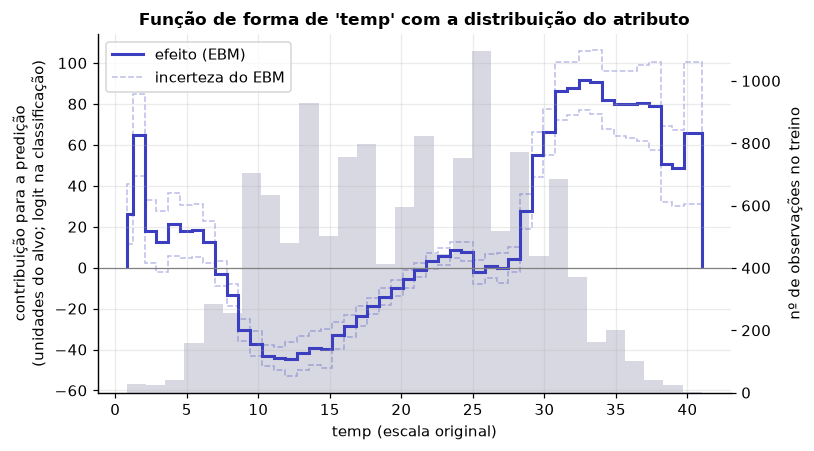

In [11]:
# Pergunta que a figura responde: o efeito deste atributo é monótono? Há limiar?
# Há alguma região em que a curva é forte mas os dados são escassos?
candidatos = ["temp", "feel_temp", "hour", "Age", "bmi", "age"]
ATRIBUTO = next(c for c in candidatos + list(X.columns) if c in X.columns)
print("atributo escolhido:", ATRIBUTO)

aditivo = modelos["ebm"]
fig, ax = plt.subplots()

if TEM_EBM:
    i = list(aditivo.term_names_).index(ATRIBUTO)
    d = aditivo.explain_global().data(i)
    bordas = np.asarray(d["names"], dtype=float)
    scores = np.asarray(d["scores"], dtype=float)
    ax.stairs(scores, bordas, color=COR["a"], linewidth=2, label="efeito (EBM)")
    if d.get("upper_bounds") is not None:
        ax.stairs(np.asarray(d["upper_bounds"]), bordas, color=COR["a"], alpha=0.35, linestyle="--")
        ax.stairs(np.asarray(d["lower_bounds"]), bordas, color=COR["a"], alpha=0.35, linestyle="--",
                  label="incerteza do EBM")
else:
    # GAM substituto: varia só o ATRIBUTO, demais atributos fixos na mediana, curva centrada
    grade = np.linspace(Xtr[ATRIBUTO].quantile(0.01), Xtr[ATRIBUTO].quantile(0.99), 100)
    base = pd.DataFrame([Xtr.median()] * len(grade))
    base[ATRIBUTO] = grade
    efeito = _saida(aditivo, base)
    ax.plot(grade, efeito - efeito.mean(), color=COR["a"], linewidth=2, label="efeito (GAM)")

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel(f"{ATRIBUTO} (escala original)")
ax.set_ylabel("contribuição para a predição\n(unidades do alvo; logit na classificação)")

# histograma do atributo no eixo secundário: onde o modelo de fato viu dados
ax2 = ax.twinx()
ax2.hist(Xtr[ATRIBUTO], bins=30, color=COR["c"], alpha=0.25)
ax2.set_ylabel("nº de observações no treino")
ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)

ax.set_title(f"Função de forma de '{ATRIBUTO}' com a distribuição do atributo")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Discussão 5.** Leia a curva como se estivesse explicando a um especialista do domínio. O que ela afirma? Há alguma região em que você se recusaria a interpretá-la, e por quê?

A curva de `temp` no EBM não é monotônica. Entre **9 °C e 15 °C**, a contribuição é negativa, chegando a cerca de **−44 aluguéis por hora** perto de 12 °C. Depois, o efeito aumenta até aproximadamente **+90** entre 31 °C e 34 °C, mas volta a cair em temperaturas mais altas, sugerindo que o calor excessivo também reduz o uso das bicicletas.

Para um especialista, a interpretação mais segura seria que existe uma faixa de temperatura mais favorável ao uso, com redução do efeito acima de aproximadamente **35 °C**. Já os picos abaixo de **3 °C** e entre **40 °C e 41 °C** não devem ser interpretados como efeitos reais, pois há poucas observações nesses intervalos e a incerteza é alta. Esses valores provavelmente refletem casos isolados.


---
## 7. Síntese

Junte as três tabelas em uma só e tome uma decisão. Não há resposta única.

In [12]:
resumo = (tabela_acuracia
          .merge(tabela_complexidade, on="modelo")
          .merge(tabela_estabilidade, on="modelo"))

# ordem em que a escolha é defendida — ajuste de acordo com a sua Discussão 6
ORDEM = ["ebm", "arvore", "linear", "gradient_boosting"]
resumo = resumo.set_index("modelo").loc[ORDEM].reset_index()
resumo

,modelo,metrica,p05,p95,largura_intervalo,unidade,elementos,detalhe,freq_topo_mais_comum,jaccard_top3
0,ebm,33.8094,32.8813,34.9430,2.0617,funções de forma + interações,96,"16 funções de forma, 80 interações",1.0,1.0
1,arvore,80.9289,78.6393,83.0594,4.4201,folhas (prof. média do caminho),16,"16 folhas, profundidade média do caminho 4.00",1.0,1.0
2,linear,103.4717,101.3693,105.7130,4.3437,coeficientes não nulos,16,16 de 16 acima de 1% do maior |coef|,0.7,0.7
3,gradient_boosting,40.8140,39.6331,42.0626,2.4295,árvores × folhas,1600,200 árvores × 8.0 folhas em média,1.0,0.7


**Discussão 6 (síntese).** Escolha um modelo para um público (e conjunto de dados / aplicação) que você vai **nomear** — médicos, analistas de crédito, auditores, engenheiros da sua equipe. Justifique com os três eixos medidos. Depois responda: o que você mediria a seguir, se tivesse mais uma semana?

Eu escolheria o **EBM** para a equipe de planejamento de um sistema de bicicletas compartilhadas, que precisa decidir quantas bicicletas redistribuir por horário e estação. Nos três critérios, ele foi o melhor: **(1) acurácia**, com MAE de **33,8**, melhor que o Gradient Boosting (40,8); **(2) estabilidade**, mantendo o mesmo atributo no topo e o mesmo top-3 nas 10 reamostragens; e **(3) complexidade**, que é seu principal ponto fraco, com 96 termos.

Para esse público, eu apresentaria as **16 funções de forma** e deixaria as 80 interações como material técnico. Se houvesse mais uma semana para complementar a análise, eu verificaria três pontos: a estabilidade das próprias curvas entre as reamostragens, e não apenas do ranking; quanto de acurácia seria perdido ao retirar as interações do EBM, reduzindo o modelo para 16 termos; e o efeito de remover `feel_temp`, já que ela é praticamente redundante com `temp`.
